<a href="https://colab.research.google.com/github/akriti404/Deep-Learning-Lab/blob/main/lab12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Episode   1 | Reward:   10.0 | Epsilon: 1.0000
Episode   2 | Reward:   11.0 | Epsilon: 0.9950
Episode   3 | Reward:   14.0 | Epsilon: 0.9900
Episode   4 | Reward:   23.0 | Epsilon: 0.9851
Episode   5 | Reward:   18.0 | Epsilon: 0.9801
Episode   6 | Reward:   18.0 | Epsilon: 0.9752
Episode   7 | Reward:   11.0 | Epsilon: 0.9704
Episode   8 | Reward:   19.0 | Epsilon: 0.9655
Episode   9 | Reward:   24.0 | Epsilon: 0.9607
Episode  10 | Reward:   12.0 | Epsilon: 0.9559
Episode  11 | Reward:   17.0 | Epsilon: 0.9511
Episode  12 | Reward:   13.0 | Epsilon: 0.9464
Episode  13 | Reward:   13.0 | Epsilon: 0.9416
Episode  14 | Reward:   15.0 | Epsilon: 0.9369
Episode  15 | Reward:   23.0 | Epsilon: 0.9322
Episode  16 | Reward:   27.0 | Epsilon: 0.9276
Episode  17 | Reward:   12.0 | Epsilon: 0.9229
Episode  18 | Reward:   11.0 | Epsilon: 0.9183
Episode  19 | Reward:   18.0 | Epsilon: 0.9137
Episode  20 | Reward:   20.0 | Epsilon: 0.9092
Episode  21 | Reward:   21.0 | Epsilon: 0.9046
Episode  22 |

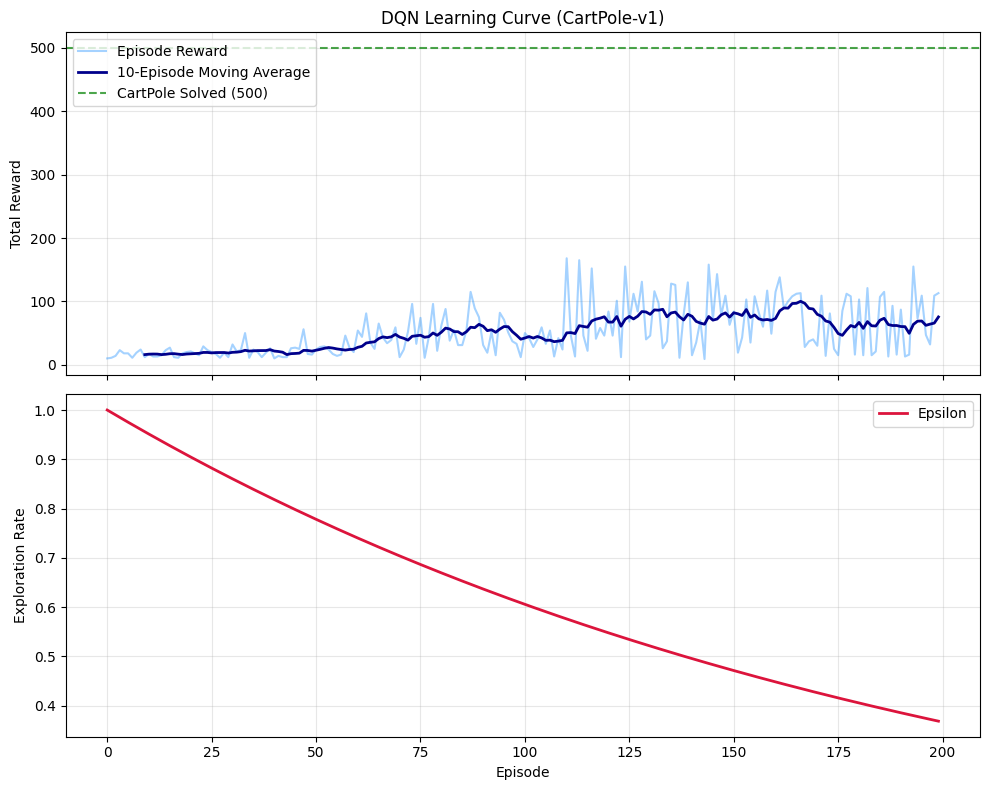

In [1]:
import random
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim


class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(QNetwork, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_dim)
        )

    def forward(self, x):
        return self.fc(x)


class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append(
            (state, action, reward, next_state, done)
        )

    def sample(self, batch_size):
        state, action, reward, next_state, done = zip(
            *random.sample(self.buffer, batch_size)
        )

        return (
            torch.FloatTensor(np.array(state)),
            torch.LongTensor(action),
            torch.FloatTensor(reward),
            torch.FloatTensor(np.array(next_state)),
            torch.FloatTensor(done)
        )

    def __len__(self):
        return len(self.buffer)


def plot_training_results(rewards, epsilons):
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 8), sharex=True
    )

    window = 10
    moving_avg = np.convolve(
        rewards, np.ones(window) / window, mode="valid"
    )

    ax1.plot(
        rewards, alpha=0.4,
        color="dodgerblue", label="Episode Reward"
    )
    ax1.plot(
        range(window - 1, len(rewards)),
        moving_avg, color="darkblue",
        linewidth=2, label="10-Episode Moving Average"
    )
    ax1.axhline(
        y=500, color="green", linestyle="--",
        alpha=0.7, label="CartPole Solved (500)"
    )
    ax1.set_ylabel("Total Reward")
    ax1.set_title("DQN Learning Curve (CartPole-v1)")
    ax1.legend(loc="upper left")
    ax1.grid(True, alpha=0.3)

    ax2.plot(
        epsilons, color="crimson",
        linewidth=2, label="Epsilon"
    )
    ax2.set_xlabel("Episode")
    ax2.set_ylabel("Exploration Rate")
    ax2.legend(loc="upper right")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("dqn_cartpole_training.png", dpi=300)
    plt.show()


def train_and_visualize_dqn():
    env = gym.make("CartPole-v1")

    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    policy_net = QNetwork(state_dim, action_dim)
    target_net = QNetwork(state_dim, action_dim)
    target_net.load_state_dict(policy_net.state_dict())

    optimizer = optim.Adam(policy_net.parameters(), lr=1e-3)
    memory = ReplayBuffer(10000)

    batch_size = 64
    gamma = 0.99
    epsilon = 1.0
    epsilon_decay = 0.995
    epsilon_min = 0.01

    rewards_history = []
    epsilon_history = []

    for episode in range(1, 201):
        state, info = env.reset()
        total_reward = 0

        while True:
            if random.random() < epsilon:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    state_tensor = torch.FloatTensor(
                        state
                    ).unsqueeze(0)
                    action = policy_net(
                        state_tensor
                    ).argmax().item()

            next_state, reward, terminated, truncated, _ = (
                env.step(action)
            )
            done = terminated or truncated

            memory.push(
                state, action, reward, next_state, float(done)
            )

            state = next_state
            total_reward += reward

            if len(memory) >= batch_size:
                b_s, b_a, b_r, b_ns, b_d = memory.sample(
                    batch_size
                )

                q_values = policy_net(b_s).gather(
                    1, b_a.unsqueeze(1)
                ).squeeze(1)

                with torch.no_grad():
                    max_next_q = target_net(b_ns).max(1)[0]
                    target_q = b_r + (
                        1 - b_d
                    ) * gamma * max_next_q

                loss = nn.MSELoss()(q_values, target_q)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            if done:
                break

        rewards_history.append(total_reward)
        epsilon_history.append(epsilon)

        print(
            f"Episode {episode:3d} | "
            f"Reward: {total_reward:6.1f} | "
            f"Epsilon: {epsilon:.4f}"
        )

        epsilon = max(
            epsilon_min, epsilon * epsilon_decay
        )

        if episode % 10 == 0:
            target_net.load_state_dict(
                policy_net.state_dict()
            )

    env.close()
    plot_training_results(
        rewards_history, epsilon_history
    )


if __name__ == "__main__":
    train_and_visualize_dqn()

In [2]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image


class ConditionalGenerator(nn.Module):
    def __init__(self, z_dim=100, num_classes=10, img_dim=784):
        super(ConditionalGenerator, self).__init__()

        self.label_emb = nn.Embedding(num_classes, num_classes)

        self.net = nn.Sequential(
            nn.Linear(z_dim + num_classes, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, img_dim),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        c = self.label_emb(labels)
        x = torch.cat([noise, c], dim=1)
        return self.net(x)


class ConditionalDiscriminator(nn.Module):
    def __init__(self, num_classes=10, img_dim=784):
        super(ConditionalDiscriminator, self).__init__()

        self.label_emb = nn.Embedding(num_classes, num_classes)

        self.net = nn.Sequential(
            nn.Linear(img_dim + num_classes, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, img, labels):
        c = self.label_emb(labels)
        x = torch.cat([img, c], dim=1)
        return self.net(x)


def train_cgan():
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    print(f"Training Conditional GAN on device: {device}")

    lr = 2e-4
    z_dim = 100
    num_classes = 10
    img_dim = 28 * 28
    batch_size = 128
    num_epochs = 5

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    dataset = datasets.MNIST(
        root="./data",
        train=True,
        transform=transform,
        download=True
    )

    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=True
    )

    gen = ConditionalGenerator(
        z_dim=z_dim,
        num_classes=num_classes,
        img_dim=img_dim
    ).to(device)

    disc = ConditionalDiscriminator(
        num_classes=num_classes,
        img_dim=img_dim
    ).to(device)

    opt_gen = optim.Adam(
        gen.parameters(), lr=lr, betas=(0.5, 0.999)
    )
    opt_disc = optim.Adam(
        disc.parameters(), lr=lr, betas=(0.5, 0.999)
    )

    criterion = nn.BCELoss()

    fixed_noise = torch.randn(20, z_dim, device=device)
    fixed_labels = torch.tensor(
        [i for i in range(10) for _ in range(2)],
        device=device
    )

    print("\n--- Starting Conditional GAN Training ---")

    for epoch in range(1, num_epochs + 1):
        for batch_idx, (real, labels) in enumerate(loader):
            real = real.view(-1, img_dim).to(device)
            labels = labels.to(device)
            current_batch_size = real.size(0)

            # Train Discriminator
            noise = torch.randn(
                current_batch_size, z_dim, device=device
            )
            fake = gen(noise, labels)

            disc_real = disc(real, labels).view(-1)
            loss_disc_real = criterion(
                disc_real, torch.ones_like(disc_real)
            )

            disc_fake = disc(
                fake.detach(), labels
            ).view(-1)
            loss_disc_fake = criterion(
                disc_fake, torch.zeros_like(disc_fake)
            )

            loss_disc = (
                loss_disc_real + loss_disc_fake
            ) / 2

            opt_disc.zero_grad()
            loss_disc.backward()
            opt_disc.step()

            # Train Generator
            output = disc(fake, labels).view(-1)
            loss_gen = criterion(
                output, torch.ones_like(output)
            )

            opt_gen.zero_grad()
            loss_gen.backward()
            opt_gen.step()

        print(
            f"Epoch [{epoch}/{num_epochs}] | "
            f"Loss D: {loss_disc.item():.4f} | "
            f"Loss G: {loss_gen.item():.4f}"
        )

        with torch.no_grad():
            fake_samples = gen(
                fixed_noise, fixed_labels
            ).reshape(-1, 1, 28, 28)

            fake_samples = fake_samples * 0.5 + 0.5

            save_image(
                fake_samples,
                f"cgan_controlled_epoch_{epoch}.png",
                nrow=4
            )

    print(
        "\nTraining completed! Check "
        "'cgan_controlled_epoch_X.png' "
        "to see generated digits."
    )


if __name__ == "__main__":
    train_cgan()


Training Conditional GAN on device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 42.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.09MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.10MB/s]



--- Starting Conditional GAN Training ---
Epoch [1/5] | Loss D: 0.6502 | Loss G: 1.1366
Epoch [2/5] | Loss D: 0.5967 | Loss G: 1.0415
Epoch [3/5] | Loss D: 0.6297 | Loss G: 0.9221
Epoch [4/5] | Loss D: 0.6520 | Loss G: 0.9696
Epoch [5/5] | Loss D: 0.5895 | Loss G: 1.0056

Training completed! Check 'cgan_controlled_epoch_X.png' to see generated digits.
